# 🧪 Notebook 14 — Sample-Based Krylov Quantum Diagonalization

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Advanced\
> **Estimated time:** 90 min\
> **Prerequisites:** SQD, time evolution, Trotterization, computational-basis sampling, and selected-CI

---

## 📌 Overview

This notebook extends SQD with time-evolved Krylov states. Configurations sampled across the evolution are accumulated into a growing subspace whose energy is recomputed as the subspace expands.

## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Generate time-evolved states for Krylov sampling.
- Accumulate unique configurations across time steps.
- Compare exact and circuit-based sampling.
- Study subspace convergence and compression effects.

## 🔑 Key concepts

`SKQD` · `Krylov sampling` · `configuration accumulation` · `Hamiltonian compression` · `shot noise` · `subspace convergence`

## 🧩 Structure

1. H₄ and FCI benchmark
2. Initial Hartree–Fock state
3. Classical time stepping
4. Exact and circuit sampling
5. Compressed subspace energies

## 📚 Resources

- PySCF, OpenFermion, Qiskit, and `qiskit_addon_sqd` documentation
- Previous notebook: `sqd.ipynb`

### ⏱️ Expected outcome

You will implement an SKQD workflow that approaches the H₄ FCI energy as time-evolved configurations enter the selected subspace.

# Sample-based Krylov quantum diagonalization

This notebook extends the SQD workflow by collecting configurations from a sequence of time-evolved states. Starting from the Hartree-Fock state, it applies approximate real-time evolution, accumulates the observed occupation strings, and solves the molecular Hamiltonian in the growing selected subspace.

The workflow is:

1. Build an H4 Hamiltonian in the STO-3G basis.
2. Map it to an eight-qubit Pauli Hamiltonian.
3. Evolve the Hartree-Fock state and collect likely configurations.
4. Recompute the selected-subspace energy after each time step.

Unlike a single-shot subspace selection, time stepping reveals configurations that are initially unlikely but become populated under the Hamiltonian dynamics.

In [1]:
import numpy as np
import qiskit
import openfermion
import pyscf
from networkx.algorithms.bipartite.basic import density

## Molecular Hamiltonian


In [2]:
# H4 molecule
from pyscf import gto, scf

# Build molecule
d=2.0
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 1*d)],
          ["H", (0.0, 0.0, 2*d)],
          ["H", (0.0, 0.0, 3*d)]
          ],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.57561647670187


np.float64(-1.5756164767018652)

The system is a linear H4 chain with nearest-neighbor spacing $d=2.0$ Angstrom. In STO-3G there are four spatial orbitals and eight spin orbitals, so the full occupation space has dimension $2^8=256$. RHF supplies the reference determinant and FCI provides the benchmark energy against which the selected-subspace result can be compared.

In [3]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
fci_energy, ci = cisolver.kernel()
print("FCI energy:", fci_energy)

FCI energy: -1.8977806459898723


### FCI reference ground state

In [4]:
tol_ampl = 0.01

from pyscf.fci import cistring
mc = cisolver

ncas = mc.norb
nelec = mc.nelec

# determinants α i β (representats com enters amb bits d’ocupació)
na, nb = nelec
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (αβ αβ ...)"""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]
    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))
    return ''.join(inter)[::-1]

print('\namplitudes FCI')
for i, a in enumerate(alpha_det):
    for j, b in enumerate(beta_det):
        amp = mc.ci[i, j]
        if amp**2 > tol_ampl:
            # print(f"α={format(a, f'0{ncas}b')}  β={format(b, f'0{ncas}b')}  coef={amp:+.6f}")
            cfg = interleave_bits(a, b, ncas)
            print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f}) ")


amplitudes FCI
11110000   +0.694100  (0.481775) 
11001100   -0.388924  (0.151262) 
01100110   +0.181096  (0.032796) 
00111100   -0.114150  (0.013030) 
10010110   +0.255203  (0.065128) 
01101001   +0.255203  (0.065128) 
11000011   -0.107524  (0.011561) 
10011001   +0.181096  (0.032796) 
00110011   -0.251266  (0.063134) 
00001111   +0.259514  (0.067347) 


### Build second quantization Hamiltonian from electronic integrals

In [5]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
# nuclear
print(e_nuc)

[[-1.13379714e+00  1.10658094e-16  9.24693961e-02  6.91712625e-17]
 [ 1.51302752e-16 -1.04226825e+00 -6.78951586e-16  7.41977398e-02]
 [ 9.24693961e-02 -6.33224594e-16 -9.78602165e-01  3.14265793e-16]
 [-1.21416383e-16  7.41977398e-02  2.94456514e-16 -9.67108698e-01]]
[[[[ 3.50481811e-01 -2.84494650e-16 -5.76182543e-02  3.81639165e-17]
   [-2.91433544e-16  1.64643593e-01 -1.11022302e-16 -3.03991509e-02]
   [-5.76182543e-02 -1.11022302e-16  1.27781482e-01 -2.15105711e-16]
   [ 2.08166817e-17 -3.03991509e-02 -2.08166817e-16  1.23346862e-01]]

  [[-2.91433544e-16  1.64643593e-01 -1.11022302e-16 -3.03991509e-02]
   [ 3.19106671e-01  2.35922393e-16  1.74272684e-02  1.04083409e-17]
   [-1.38777878e-17  6.97056778e-02  1.59594560e-16  1.03951062e-01]
   [-5.98408006e-02  2.08166817e-17  1.29023423e-01 -2.77555756e-16]]

  [[-5.76182543e-02 -1.11022302e-16  1.27781482e-01 -2.15105711e-16]
   [-1.38777878e-17  6.97056778e-02  1.59594560e-16  1.03951062e-01]
   [ 3.22145549e-01  2.49800181e-16  

In [6]:
from openfermion import InteractionOperator, jordan_wigner
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)
ha_qubit = jordan_wigner(hamiltonian)


## Initial HF state preparation

The reference state occupies spin orbitals 0 through 3, represented by `0^ 1^ 2^ 3^`.

In [7]:
from openfermion import FermionOperator
# a b a b a b
state = FermionOperator('0^ 1^ 2^ 3^')

## Selected-configuration energy

`get_sci_energy` converts each eight-bit occupation string into separate alpha and beta occupation integers, then calls `solve_fermion` on only those configurations. The returned electronic energy is combined with the Hamiltonian constant to recover the total molecular energy.

In [8]:
from qiskit_addon_sqd.fermion import solve_fermion


def get_sci_energy(configuration_list):

    up_list = []
    down_list = []
    for fock_vector in configuration_list:

        bitstring = ''.join(str(bit) for bit in fock_vector)

        up_str = ''.join(
            '0' if i % 2 == 0 else bit
            for i, bit in enumerate(bitstring)
        )

        down_str = ''.join(
            bit if i % 2 == 0 else '0'
            for i, bit in enumerate(bitstring)
        )

        up_list.append(int(up_str, 2))
        down_list.append(int(down_str, 2))

    up = np.array(up_list, dtype=np.uint32)
    down = np.array(down_list, dtype=np.uint32)

    inv = np.argsort((0, 2, 3, 1))
    # Hamiltonian absorbs 1/2 into the coefficients. To recover 2e integrals should be multiplied by 2
    two_body_tensor_restored = hamiltonian.two_body_tensor.transpose(inv) * 2


    energy_sci, coeffs_sci, avg_occs, spin = solve_fermion((up, down),
                                                           hamiltonian.one_body_tensor,
                                                           two_body_tensor_restored,
                                                           open_shell=False,
                                                           #spin_sq=0,
                                                           )

    return energy_sci + hamiltonian.constant # total energy


## Compute the subspace Hamiltonian matrix (exact)

To imporve the quanlty of the sampling we evolve the initial state with a time evolution operator, and we sample new bit strings that are added to a set. Because the set retains unique configurations across time, the subspace can only grow and the energy decrease. After each update, the Hamiltonian is diagonalized in the accumulated subspace.

In [9]:
from scipy.sparse.linalg import expm, expm_multiply


def time_evolution_trotter(t):
    vec = get_sparse_operator(state, n_qubits=8)
    for op in ha_qubit.get_operators():
        sparse_op =-1j*t * get_sparse_operator(op, n_qubits=8)
        vec = expm_multiply(sparse_op, vec)
    return vec


time:  0.0
sum squares:  1.0
00001111 1.0
Subspace energy:  -1.5756164767018652

time:  0.05
sum squares:  0.9999999999999994
00001111 0.9996842708349173
Subspace energy:  -1.5756164767018652

time:  0.1
sum squares:  1.0000000000000018
00001111 0.9987379367114769
00110011 0.00021181215543640824
11000011 0.00017401817116578504
10010110 0.0001662675877714691
01101001 0.00016622420915446802
00111100 0.0001630073268309577
11001100 0.00015190755438458648
01100110 0.00010793144675310575
10011001 0.00010786426612437328
Subspace energy:  -1.8519308371026533

time:  0.15000000000000002
sum squares:  1.0000000000000009
00001111 0.9971635556120919
00110011 0.00047613991832196696
11000011 0.0003910906123207679
10010110 0.00037353239032852475
01101001 0.000373312955185784
00111100 0.0003659979246416381
11001100 0.0003411266487255615
01100110 0.0002424898203252268
10011001 0.000242150185080227
Subspace energy:  -1.8519308371026533

time:  0.2
sum squares:  0.9999999999999992
00001111 0.99496538372

Text(0, 0.5, 'Subspace energy [Ha]')

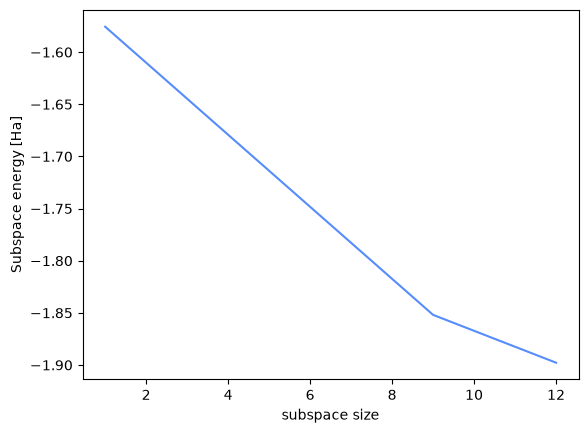

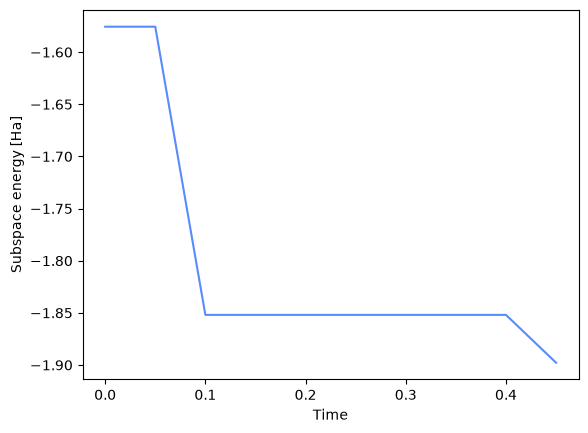

In [10]:
import numpy as np
from openfermion import get_sparse_operator
import matplotlib.pyplot as plt

# define a set of unique values
configuration_list = set()

dt = 0.05
energies = []
subspace_size = []
times = []
for t in np.arange(0, 0.5, dt):

    print('\ntime: ', t)

    sparse_state = time_evolution_trotter(t)

    probs = np.abs(sparse_state.toarray()[:,0])**2
    print('sum squares: ', sum(probs))

    def binary_strings(n, width):
        for i in range(n):
            yield format(i, f'0{width}b')[::-1] # revert to have the same order as qiskit

    tol_ampl = 1e-4
    prob_exact = {}
    for b, p  in zip(binary_strings(2**8, 8), probs):
        if p > tol_ampl:
            prob_exact[b] = p

    prob_ordered = dict(sorted(prob_exact.items(), key=lambda item: -item[1]))
    for k, v in prob_ordered.items():
        print(k, v)

    # update configuration list
    configuration_list.update(list(prob_ordered.keys()))

    energy = get_sci_energy(configuration_list)
    print('Subspace energy: ', energy)

    energies.append(energy)
    subspace_size.append(len(configuration_list))
    times.append(t)


print('\nFinal energy: ', energies[-1])
plt.plot(subspace_size, energies)
plt.xlabel('subspace size')
plt.ylabel('Subspace energy [Ha]')

plt.figure()
plt.plot(times, energies)
plt.xlabel('Time')
plt.ylabel('Subspace energy [Ha]')


The classical time-stepping experiment shows the mechanism of SKQD: at early times only the reference configuration may be present, while later evolution populates additional determinants. Once the selected set contains the important configurations, the subspace energy reaches the FCI benchmark.

## Time evolution implemented in a quantum circuit

In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

te_qubit = -1j * ha_qubit

# limit the size of the circuit
te_qubit.compress(1e-2)


# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc = QuantumCircuit(8)

#reference
qc.x(0)
qc.x(1)
qc.x(2)
qc.x(3)

# time evolution
i_op = 0
for op, coef in te_qubit.terms.items():

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*theta * coef.imag, op[0][0])

    for qubit, pauli in reversed(op[1:]):
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(-np.pi / 2, [qubit])

    qc.barrier()

print('depth', qc.depth())
# qc.draw('mpl') # BE CAREFUL uncommenting this! Large circuits consume a lot of RAM

depth 1113



The circuit uses the same Hartree-Fock reference and Pauli-term decomposition as the classical propagator. `theta` represents the evolution time. For this example we use `compress(1e-2)` to reduce the size of the Hamiltonian by removing terms below the chosen coefficient threshold to reduce circuit size. The resulting depth illustrates the cost of a direct, unoptimized decomposition.

## Compute the subspace Hamiltonian matrix (quantum circuit)


time:  0.0
00001111 1.0
Subspace energy:  -1.5756164767018652

time:  0.05
00001111 0.9998
11001100 0.0001
01101001 0.0001
Subspace energy:  -1.679511917849715

time:  0.1
00001111 0.9989
00110011 0.0002
11001100 0.0002
11000011 0.0002
00111100 0.0002
01101001 0.0001
10011001 0.0001
10010110 0.0001
Subspace energy:  -1.8519308371026533

time:  0.15000000000000002
00001111 0.9976
11001100 0.0006
10010110 0.0004
01101001 0.0004
01100110 0.0003
11000011 0.0002
00110011 0.0002
00111100 0.0002
10011001 0.0001
Subspace energy:  -1.8519308371026533

time:  0.2
00001111 0.9953
00110011 0.001
10010110 0.0007
01100110 0.0006
01101001 0.0005
11001100 0.0004
11000011 0.0004
00111100 0.0003
10011001 0.0003
10000111 0.0002
00011110 0.0001
10100101 0.0001
01001011 0.0001
Subspace energy:  -1.8536279460139187

time:  0.25
00001111 0.9917
11000011 0.0015
00110011 0.0012
01100110 0.0011
01101001 0.0011
00111100 0.001
10010110 0.0008
11001100 0.0006
10011001 0.0004
10100101 0.0003
00011110 0.0002
100001

Text(0, 0.5, 'Subspace energy [Ha]')

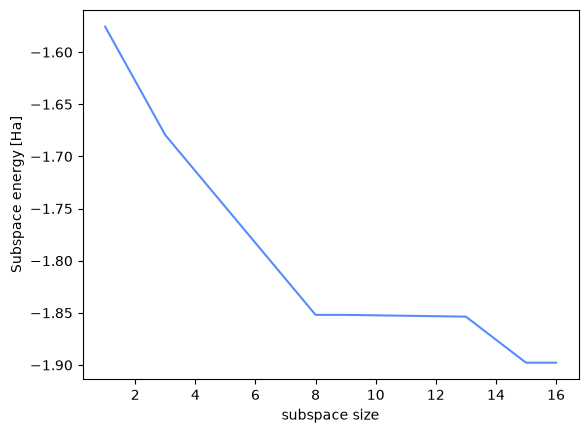

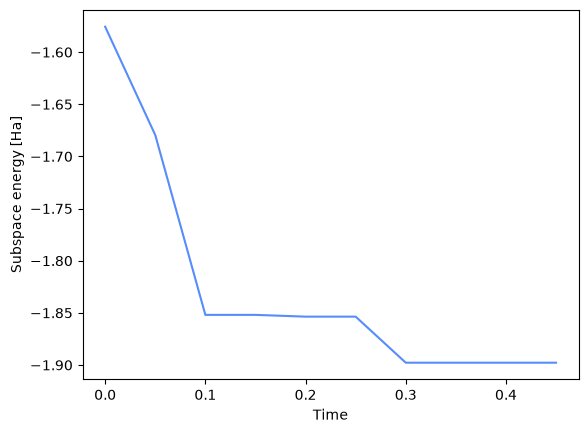

In [12]:
from qiskit.primitives import StatevectorSampler

# define a set of unique values
configuration_list = set()

dt = 0.05
energies = []
subspace_size = []
times = []
for t in np.arange(0, 0.5, dt):

    print('\ntime: ', t)

    sampler = StatevectorSampler()

    qc_meas = qc.assign_parameters([t])
    qc_meas.measure_all()

    result = sampler.run([qc_meas], shots=10000).result()
    counts = result[0].data.meas.get_counts()
    shots = sum(counts.values())

    counts_ordered = dict(sorted(counts.items(), key=lambda item: -item[1]))
    for k, v in counts_ordered.items():
        print(k, v/shots)

    # update configuration list
    configuration_list.update(list(counts_ordered.keys()))

    energy = get_sci_energy(configuration_list)
    print('Subspace energy: ', energy)

    energies.append(energy)
    subspace_size.append(len(configuration_list))
    times.append(t)

print('\nFinal energy: ', energies[-1])
plt.plot(subspace_size, energies)
plt.xlabel('subspace size')
plt.ylabel('Subspace energy [Ha]')

plt.figure()
plt.plot(times, energies)
plt.xlabel('Time')
plt.ylabel('Subspace energy [Ha]')



## Quantum sampling and interpretation

At each time step, the parameterized circuit is bound, measured for 10,000 shots, and its observed bit strings are merged into the persistent configuration set. Shot noise can introduce or omit rare configurations, so increasing the shot count and comparing repeated runs are useful robustness checks.

The two plots track energy against accumulated subspace size and against evolution time. Useful experiments include changing the time range, time step, and Hamiltonian compression threshold, then comparing circuit-derived convergence with the FCI reference.

Interesting tests:
- Change the time range, time step, and Hamiltonian compression threshold
- Compare circuit-derived convergence with the FCI reference.